# QGNet_Pytorch — validation against the NumPy `qgsw-DI` model

This notebook is the reference check that the PyTorch port reproduces the
original NumPy/SciPy quasigeostrophic shallow-water model.

It covers

1. operator-by-operator agreement (`h2pv`, `h2uv`, `qrhs`, `pv2h`),
2. whole-trajectory agreement over 5 and 30 days,
3. the sensitivity of the result to precision (float64 vs float32),
4. autograd versus finite differences, which is what replaces the original
   tangent-linear / adjoint pair,
5. a timing comparison.

The NumPy model is the parent `qgsw-DI` repository; set `QGSW_DI_PATH` to
point somewhere else.


## 1. Setup

In [1]:
import os, sys, time, math
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

TORCH_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
REPO_PARENT = TORCH_ROOT.parent          # the qgsw-DI repository root

def _find_numpy_root():
    env = os.environ.get("QGSW_DI_PATH")
    cands = [Path(env)] if env else []
    cands += [REPO_PARENT, REPO_PARENT / "qgsw-DI"]
    for d in cands:
        if (d / "qgsw.py").is_file() and (d / "modgrid.py").is_file():
            return d.resolve()
    raise FileNotFoundError("qgsw-DI not found; set QGSW_DI_PATH")

NUMPY_ROOT = _find_numpy_root()

for p in (str(REPO_PARENT), str(NUMPY_ROOT)):
    if p not in sys.path:
        sys.path.insert(0, p)

if not hasattr(np, "NAN"):          # let an older qgsw-DI copy run on numpy>=2
    np.NAN = np.nan

import modgrid as np_modgrid          # the original NumPy package
import moddyn as np_moddyn
import modelliptic as np_modelliptic
import qgsw as np_qgsw

from QGNet_Pytorch import modgrid as pt_modgrid
from QGNet_Pytorch import moddyn as pt_moddyn
from QGNet_Pytorch import modelliptic as pt_modelliptic
from QGNet_Pytorch import qgsw as pt_qgsw

print("numpy", np.__version__, "| torch", torch.__version__)
print("numpy model :", NUMPY_ROOT)
print("torch model :", TORCH_ROOT)

T = lambda x, d=torch.float64: torch.as_tensor(np.ascontiguousarray(x), dtype=d)
N = lambda x: x.detach().cpu().numpy()
torch.set_grad_enabled(False)

numpy 1.26.4 | torch 2.15.0
numpy model : /Users/redouanelguensat/Desktop/QGNet/qgsw-DI
torch model : /Users/redouanelguensat/Desktop/QGNet/qgsw-DI/QGNet_Pytorch


torch.autograd.grad_mode.set_grad_enabled(mode=False)

## 2. Load the shared Gulf Stream test case

`ssh.nc` is a single NATL60-derived SSH snapshot, 113x170, 19% land.

In [2]:
import netCDF4

SSH_NC = next(p for p in (TORCH_ROOT / "ssh.nc", NUMPY_ROOT / "ssh.nc") if p.is_file())
with netCDF4.Dataset(SSH_NC) as nc:
    SSH  = np.array(nc.variables["SSH"][0, :, :], dtype="float64")
    SSHm = np.array(nc.variables["SSHm"][:, :],   dtype="float64")
    lon1d = np.array(nc.variables["lon"][:], dtype="float64")
    lat1d = np.array(nc.variables["lat"][:], dtype="float64")

SSH  = np.where(np.isfinite(SSH),  SSH,  np.nan)     # land must be NaN
SSHm = np.where(np.isfinite(SSHm), SSHm, np.nan)
lon, lat = np.meshgrid(lon1d, lat1d)
c = np.zeros_like(SSH) + 2.5                          # Rossby phase speed, m/s

print(f"shape {SSH.shape}, land {int(np.isnan(SSH).sum())} px "
      f"({np.isnan(SSH).mean():.1%}), SSH in [{np.nanmin(SSH):.3f}, {np.nanmax(SSH):.3f}] m")

shape (113, 170), land 3716 px (19.3%), SSH in [-1.565, 1.095] m


## 3. Grid parity

Everything must match exactly except `dx`, where `math.cos` (scalar libm, used by NumPy) and the vectorised `torch.cos` kernel differ in the last place.

In [3]:
gn = np_modgrid.grid(SSH.copy(), c.copy(), 0., lon.copy(), lat.copy())
gt = pt_modgrid.grid(T(SSH), T(c), 0., T(lon), T(lat))

def compare(name, a, b):
    a, b = np.asarray(a, dtype="float64"), np.asarray(b, dtype="float64")
    na, nb = np.isnan(a), np.isnan(b)
    assert np.array_equal(na, nb), f"{name}: NaN patterns differ"
    fa, fb = a[~na], b[~nb]
    if fa.size == 0:
        return name, 0.0, 0.0, 0.0
    d = np.abs(fa - fb)
    ulp = np.max(d / np.spacing(np.abs(fa) + 1e-300))
    return name, float(d.max()), float(d.max() / max(np.abs(fa).max(), 1.0)), float(ulp)

rows = [compare(a, getattr(gn, a), N(getattr(gt, a)))
        for a in ("mask", "dx", "dy", "f0", "c", "dx1d", "dy1d", "f01d", "c1d", "H")]
rows += [(a, 0.0, 0.0, 0.0) if np.array_equal(np.asarray(getattr(gn, a)), N(getattr(gt, a)))
         else (a, np.inf, np.inf, np.inf)
         for a in ("indi", "indj", "vp1", "vp2", "indp", "vp2n", "vp2s", "vp2e", "vp2w")]

print(f"{'attribute':<12s} {'max|d|':>12s} {'relative':>12s} {'ULP':>6s}")
for name, amax, rel, ulp in rows:
    print(f"{name:<12s} {amax:12.3e} {rel:12.3e} {ulp:6.1f}")
print()
print("scalars:", {a: (getattr(gn, a), getattr(gt, a)) for a in ("np", "np2", "ny", "nx")})

attribute          max|d|     relative    ULP
mask            0.000e+00    0.000e+00    0.0
dx              3.638e-12    1.984e-16    2.0
dy              0.000e+00    0.000e+00    0.0
f0              1.355e-20    1.355e-20    1.0
c               0.000e+00    0.000e+00    0.0
dx1d            3.638e-12    1.984e-16    2.0
dy1d            0.000e+00    0.000e+00    0.0
f01d            1.355e-20    1.355e-20    1.0
c1d             0.000e+00    0.000e+00    0.0
H               0.000e+00    0.000e+00    0.0
indi            0.000e+00    0.000e+00    0.0
indj            0.000e+00    0.000e+00    0.0
vp1             0.000e+00    0.000e+00    0.0
vp2             0.000e+00    0.000e+00    0.0
indp            0.000e+00    0.000e+00    0.0
vp2n            0.000e+00    0.000e+00    0.0
vp2s            0.000e+00    0.000e+00    0.0
vp2e            0.000e+00    0.000e+00    0.0
vp2w            0.000e+00    0.000e+00    0.0

scalars: {'np': (15494, 15494), 'np2': (14108, 14108), 'ny': (113, 113), 'nx': 

## 4. Operator parity

In [4]:
h = SSH.copy()
results = {}

qn,  = np_modelliptic.h2pv(h.copy(), gn)
qt,  = pt_modelliptic.h2pv(T(h), gt)
results["h2pv"] = (qn, N(qt))

un, vn = np_moddyn.h2uv(h.copy(), gn)
ut, vt = pt_moddyn.h2uv(T(h), gt)
results["h2uv u"] = (un, N(ut))
results["h2uv v"] = (vn, N(vt))

for way in (1., -1.):
    rn, = np_moddyn.qrhs(un.copy(), vn.copy(), qn.copy(), gn, way)
    rt, = pt_moddyn.qrhs(T(un), T(vn), T(qn), gt, way)
    results[f"qrhs way={way:+.0f}"] = (rn, N(rt))

hg = np.nan_to_num(h, nan=0.) * 1.01
for nitr in (1, 2, 5, 25):
    hn, = np_modelliptic.pv2h(qn.copy(), hg.copy(), gn, nitr)
    ht, = pt_modelliptic.pv2h(T(qn), T(hg), gt, nitr)
    results[f"pv2h nitr={nitr}"] = (hn, N(ht))

print(f"{'operator':<16s} {'max|d|':>12s} {'relative':>12s}")
for k, (a, b) in results.items():
    d = np.abs(a - b)
    print(f"{k:<16s} {np.nanmax(d):12.3e} {np.nanmax(d)/max(np.nanmax(np.abs(a)),1e-30):12.3e}")

operator               max|d|     relative
h2pv                5.421e-20    2.089e-16
h2uv u              4.441e-16    1.956e-16
h2uv v              4.441e-16    2.226e-16
qrhs way=+1         1.654e-24    1.460e-16
qrhs way=-1         1.241e-24    1.451e-16
pv2h nitr=1         2.220e-16    1.404e-16
pv2h nitr=2         2.220e-16    1.404e-16
pv2h nitr=5         3.331e-16    2.107e-16
pv2h nitr=25        4.441e-16    2.809e-16


## 5. Trajectory parity over 5 days

`dt = 600 s`, so this is 720 explicit Euler steps each followed by one conjugate-gradient inversion.

In [5]:
kw = dict(tint=5*86400., dtout=86400., dt=600., snu=0.)   # snu=0., NOT None

t0 = time.perf_counter()
Hn, _ = np_qgsw.qgsw(Hi=SSH.copy(), c=c.copy(), lon=lon.copy(), lat=lat.copy(), **kw)
t_np = time.perf_counter() - t0

t0 = time.perf_counter()
Ht, _ = pt_qgsw.qgsw(Hi=T(SSH), c=T(c), lon=T(lon), lat=T(lat), **kw)
t_pt = time.perf_counter() - t0
Ht = N(Ht)

print(f"numpy {t_np:.2f} s | torch {t_pt:.2f} s | speedup {t_np/t_pt:.2f}x\n")
print(f"{'day':>4s} {'max|numpy-torch|':>18s} {'rmse':>12s} {'MSE':>12s}")
for k in range(Hn.shape[0]):
    d = np.abs(Hn[k] - Ht[k])
    print(f"{k:>4d} {np.nanmax(d):18.3e} {np.sqrt(np.nanmean(d**2)):12.3e} {np.nanmean(d**2):12.3e}")
assert np.array_equal(np.isnan(Hn), np.isnan(Ht)), "land masks diverged"

numpy 2.59 s | torch 1.49 s | speedup 1.74x

 day   max|numpy-torch|         rmse          MSE
   0          0.000e+00    0.000e+00    0.000e+00
   1          4.441e-16    7.845e-17    6.155e-33
   2          5.551e-16    8.127e-17    6.605e-33
   3          5.551e-16    8.866e-17    7.860e-33
   4          5.551e-16    8.908e-17    7.935e-33
   5          5.551e-16    9.434e-17    8.901e-33


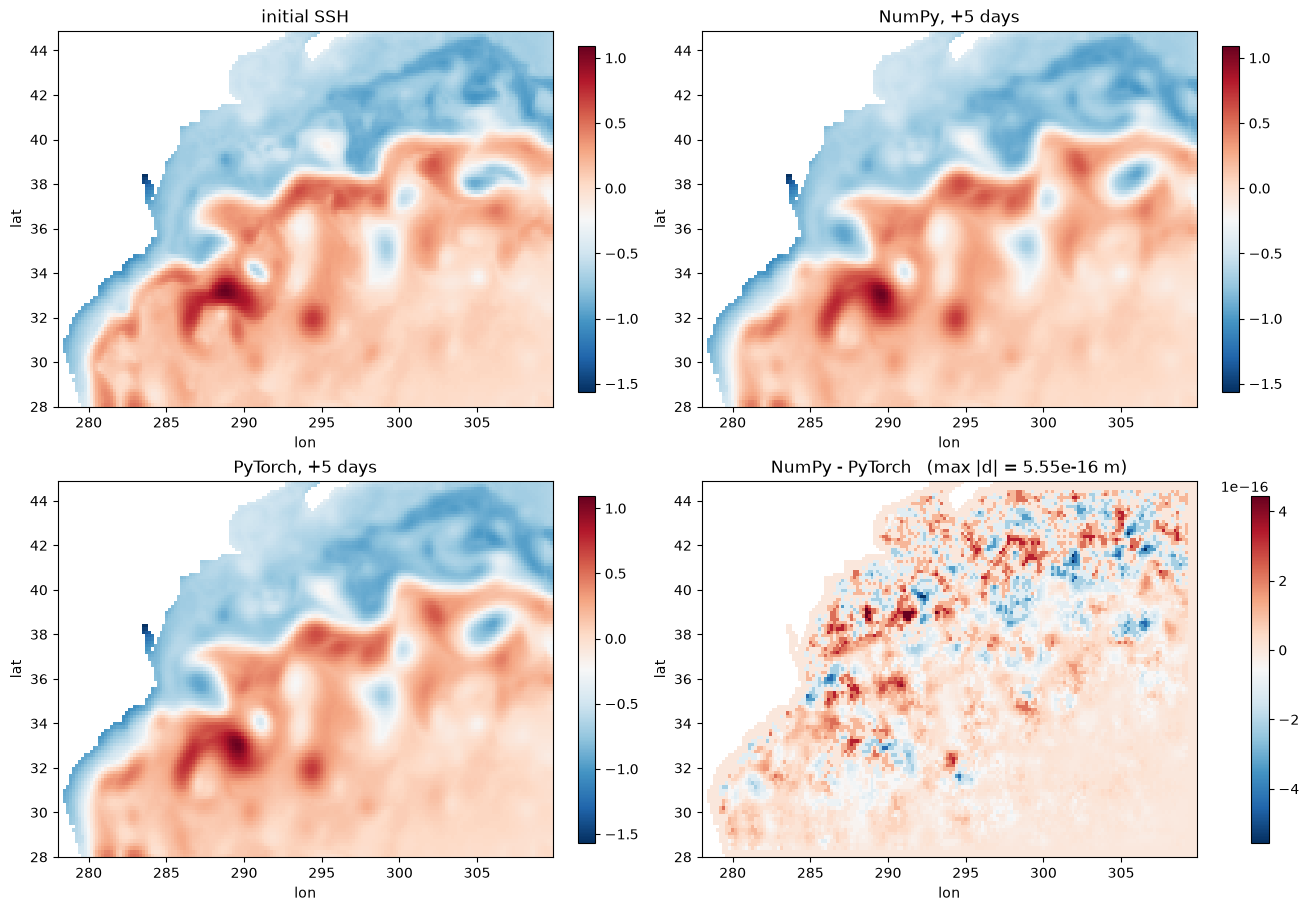

In [6]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)
vmin, vmax = np.nanmin(SSH), np.nanmax(SSH)

im = ax[0,0].pcolormesh(lon, lat, SSH, vmin=vmin, vmax=vmax, shading="auto", cmap="RdBu_r")
ax[0,0].set_title("initial SSH")
plt.colorbar(im, ax=ax[0,0], fraction=0.035)

im = ax[0,1].pcolormesh(lon, lat, Hn[-1], vmin=vmin, vmax=vmax, shading="auto", cmap="RdBu_r")
ax[0,1].set_title("NumPy, +5 days")
plt.colorbar(im, ax=ax[0,1], fraction=0.035)

im = ax[1,0].pcolormesh(lon, lat, Ht[-1], vmin=vmin, vmax=vmax, shading="auto", cmap="RdBu_r")
ax[1,0].set_title("PyTorch, +5 days")
plt.colorbar(im, ax=ax[1,0], fraction=0.035)

diff = Hn[-1] - Ht[-1]
im = ax[1,1].pcolormesh(lon, lat, diff, shading="auto", cmap="RdBu_r")
ax[1,1].set_title(f"NumPy - PyTorch   (max |d| = {np.nanmax(np.abs(diff)):.2e} m)")
plt.colorbar(im, ax=ax[1,1], fraction=0.035)

for a in ax.ravel():
    a.set_xlabel("lon"); a.set_ylabel("lat")
plt.show()

## 6. Does the roundoff difference amplify?

The model is nonlinear and chaotic, so a 1e-16 seed *could* grow. Run 30 days (4320 steps) and watch.

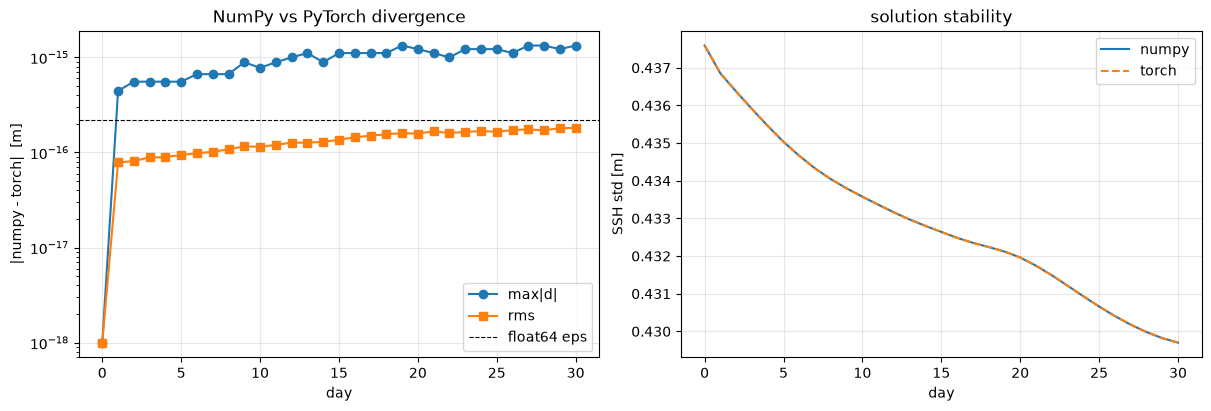

after 30 days (4320 steps): max|d| = 1.332e-15 m


In [7]:
kw_long = dict(tint=30*86400., dtout=86400., dt=600., snu=0.)
Hn30, _ = np_qgsw.qgsw(Hi=SSH.copy(), c=c.copy(), lon=lon.copy(), lat=lat.copy(), **kw_long)
Ht30 = N(pt_qgsw.qgsw(Hi=T(SSH), c=T(c), lon=T(lon), lat=T(lat), **kw_long)[0])

days = np.arange(Hn30.shape[0])
err  = np.array([np.nanmax(np.abs(Hn30[k] - Ht30[k])) for k in days])
rms  = np.array([np.sqrt(np.nanmean((Hn30[k] - Ht30[k])**2)) for k in days])

fig, ax = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
ax[0].semilogy(days, np.maximum(err, 1e-18), "o-", label="max|d|")
ax[0].semilogy(days, np.maximum(rms, 1e-18), "s-", label="rms")
ax[0].axhline(np.finfo(np.float64).eps, ls="--", c="k", lw=.8, label="float64 eps")
ax[0].set_xlabel("day"); ax[0].set_ylabel("|numpy - torch|  [m]")
ax[0].set_title("NumPy vs PyTorch divergence"); ax[0].legend(); ax[0].grid(alpha=.3)

ax[1].plot(days, [np.nanstd(Hn30[k]) for k in days], label="numpy")
ax[1].plot(days, [np.nanstd(Ht30[k]) for k in days], "--", label="torch")
ax[1].set_xlabel("day"); ax[1].set_ylabel("SSH std [m]")
ax[1].set_title("solution stability"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.show()

print(f"after 30 days ({int(30*86400/600)} steps): max|d| = {err[-1]:.3e} m")

## 7. Precision matters

float32 is fine for training a correction network but is not a substitute for the reference solver. Apple MPS only supports float32.

In [8]:
rows = []
for dtype in (torch.float64, torch.float32):
    S = N(pt_qgsw.qgsw(Hi=T(SSH, dtype), c=T(c, dtype), lon=T(lon, dtype),
                       lat=T(lat, dtype), tint=86400., dtout=86400., dt=600., snu=0.)[0])
    d = np.abs(S[-1].astype("float64") - Hn[1])
    rows.append((str(dtype), np.nanmax(d), np.sqrt(np.nanmean(d**2))))

if torch.backends.mps.is_available():
    dev = torch.device("mps")
    S = pt_qgsw.qgsw(Hi=T(SSH, torch.float32).to(dev), c=T(c, torch.float32).to(dev),
                     lon=T(lon, torch.float32).to(dev), lat=T(lat, torch.float32).to(dev),
                     tint=86400., dtout=86400., dt=600., snu=0.)[0]
    d = np.abs(N(S.cpu())[-1].astype("float64") - Hn[1])
    rows.append(("mps float32", np.nanmax(d), np.sqrt(np.nanmean(d**2))))

print(f"{'config':<22s} {'max|d| vs numpy':>18s} {'rmse':>12s}   (1 simulated day)")
for name, a, b in rows:
    print(f"{name:<22s} {a:18.3e} {b:12.3e}")

config                    max|d| vs numpy         rmse   (1 simulated day)
torch.float64                   4.441e-16    7.845e-17
torch.float32                   2.686e-07    4.509e-08
mps float32                     2.916e-07    4.363e-08


## 8. Autograd replaces the tangent-linear / adjoint pair

`qgsw_tgl.py` / `qgsw_adj.py` are not ported. Autograd is both simpler and *more* correct: the original `moddyn.qrhs_adj` is only an exact transpose of `qrhs_tgl` when the caller projects onto `mask == 2`.

In [9]:
torch.set_grad_enabled(True)

def cost(h):
    S, _ = pt_qgsw.qgsw(Hi=h, c=T(c), lon=T(lon), lat=T(lat),
                        tint=3*3600., dtout=3*3600., dt=600., snu=0.)
    out = S[-1]
    return (out[torch.isfinite(out)]**2).sum()

h0 = T(SSH).clone().requires_grad_(True)
J = cost(h0)
J.backward()
g_ad = h0.grad.clone()
print(f"J = {float(J.detach()):.8e}")
print(f"grad: finite={bool(torch.isfinite(g_ad).all())}, "
      f"non-zero at {int((g_ad != 0).sum())}/{g_ad.numel()} cells")

rng = np.random.default_rng(0)
wet = np.argwhere(gn.mask == 2)
pick = wet[rng.choice(len(wet), 8, replace=False)]
eps = 1e-6
print(f"\n{'cell':>12s} {'autograd':>18s} {'finite diff':>18s} {'rel err':>10s}")
worst = 0.
with torch.no_grad():
    for i, j in pick:
        hp = T(SSH).clone(); hp[i, j] += eps
        hm = T(SSH).clone(); hm[i, j] -= eps
        fd = (float(cost(hp)) - float(cost(hm))) / (2*eps)
        ad = float(g_ad[i, j])
        rel = abs(ad - fd) / max(abs(ad), abs(fd), 1e-30)
        worst = max(worst, rel)
        print(f"{str((i,j)):>12s} {ad:18.9e} {fd:18.9e} {rel:10.2e}")
print(f"\nworst relative error {worst:.2e}  (finite-difference truncation, not a model error)")

J = 3.42477376e+03
grad: finite=True, non-zero at 15494/19210 cells

        cell           autograd        finite diff    rel err


    (88, 66)   -9.499664186e-01   -9.499667613e-01   3.61e-07


    (8, 119)    1.320533577e-01    1.320534011e-01   3.29e-07


     (3, 84)    1.500421532e-01    1.500420694e-01   5.58e-07


   (49, 130)    5.434953370e-01    5.434953891e-01   9.59e-08


    (29, 59)    1.773811507e+00    1.773811391e+00   6.51e-08


   (25, 137)    5.852882910e-02    5.852893992e-02   1.89e-06


    (5, 112)    6.563633509e-02    6.563618626e-02   2.27e-06


    (63, 66)   -1.695456877e+00   -1.695456831e+00   2.73e-08

worst relative error 2.27e-06  (finite-difference truncation, not a model error)


In [10]:
# the gold standard: torch.autograd.gradcheck on a small land-free problem
ny, nx = 12, 14
lo_s, la_s = np.meshgrid(300. + .1875*np.arange(nx), 30. + .15*np.arange(ny))
yy, xx = np.mgrid[0:ny, 0:nx]
ssh_s = (.4*np.sin(2*np.pi*xx/nx)*np.cos(2*np.pi*yy/ny) + .2*np.sin(6*np.pi*xx/nx + 1.)
         + .05*np.random.default_rng(0).standard_normal((ny, nx)))
c_s = np.zeros_like(ssh_s) + 1.5

def f(h):
    S, _ = pt_qgsw.qgsw(Hi=h, c=T(c_s), lon=T(lo_s), lat=T(la_s),
                        tint=1200., dtout=1200., dt=600., snu=0.)
    return S[-1][3:-4, 3:-4]

ok = torch.autograd.gradcheck(f, (T(ssh_s).requires_grad_(True),),
                              eps=1e-6, atol=1e-6, rtol=1e-4)
print("torch.autograd.gradcheck:", "PASSED" if ok else "FAILED")

torch.autograd.gradcheck: PASSED


### A caveat worth knowing: the model is only *piecewise* differentiable

The PV advection uses an upwind flux split,

```python
scaled = way * 0.5 * (u[i,j] + u[i,j+1])
uplus  = where(scaled <  0, 0, scaled)
uminus = where(scaled >  0, 0, scaled)
```

which has a kink wherever a face velocity crosses zero. Autograd returns a
valid one-sided derivative there; a central finite difference straddles the
kink and disagrees. The cell below constructs that degenerate situation on
purpose with a purely analytic SSH field whose face velocities are exactly
zero to machine precision.

This is a property of the numerical scheme, not a bug in the port — the
original NumPy adjoint has exactly the same kink. With real (noisy) SSH fields
face velocities are never exactly zero, so it does not bite in practice.

In [11]:
ssh_sym = .4*np.sin(2*np.pi*xx/nx)*np.cos(2*np.pi*yy/ny) + .2*np.sin(6*np.pi*xx/nx + 1.)
g_sym = pt_modgrid.grid(T(ssh_sym), T(c_s), 0., T(lo_s), T(la_s))
with torch.no_grad():
    u_s, v_s = pt_moddyn.h2uv(T(ssh_sym), g_sym)
    u_face = 0.5*(u_s[2:-2, 2:-2] + u_s[2:-2, 3:-1])
print(f"smallest |u_face| on the symmetric field: {float(u_face.abs().min()):.2e}"
      "   <- sits exactly on the upwind kink")

def f_sym(h):
    S, _ = pt_qgsw.qgsw(Hi=h, c=T(c_s), lon=T(lo_s), lat=T(la_s),
                        tint=1200., dtout=1200., dt=600., snu=0.)
    return S[-1][3:-4, 3:-4]

try:
    torch.autograd.gradcheck(f_sym, (T(ssh_sym).requires_grad_(True),),
                             eps=1e-6, atol=1e-6, rtol=1e-4)
    print("gradcheck on the symmetric field: PASSED")
except Exception as exc:
    print("gradcheck on the symmetric field: FAILED, as expected at a kink")
    print(" ", str(exc).splitlines()[0])

torch.set_grad_enabled(False)

smallest |u_face| on the symmetric field: 5.46e-17   <- sits exactly on the upwind kink


gradcheck on the symmetric field: FAILED, as expected at a kink
  Jacobian mismatch for output 0 with respect to input 0,


torch.autograd.grad_mode.set_grad_enabled(mode=False)

## 9. Timing

The PyTorch port wins more as the domain grows. Reusing a prebuilt grid across calls matters a lot for training loops, where the same geometry is integrated thousands of times.

In [12]:
print(f"{'size':>10s} {'numpy':>9s} {'torch':>9s} {'speedup':>8s}")
for n in (64, 128, 256):
    lo_, la_ = np.meshgrid(300. + .1875*np.arange(n), 30. + .15*np.arange(n))
    yy, xx = np.mgrid[0:n, 0:n]
    s_ = .4*np.sin(2*np.pi*xx/n)*np.cos(2*np.pi*yy/n)
    c_ = np.zeros_like(s_) + 1.5
    k = dict(tint=14400., dtout=14400., dt=600., snu=0.)
    t0 = time.perf_counter(); np_qgsw.qgsw(Hi=s_.copy(), c=c_.copy(), lon=lo_, lat=la_, **k); a = time.perf_counter()-t0
    t0 = time.perf_counter(); pt_qgsw.qgsw(Hi=T(s_), c=T(c_), lon=T(lo_), lat=T(la_), **k); b = time.perf_counter()-t0
    print(f"{n:>5d}x{n:<4d} {a:8.3f}s {b:8.3f}s {a/b:7.2f}x")

# grid reuse
k = dict(tint=3600., dtout=3600., dt=600., snu=0.)
t0 = time.perf_counter()
for _ in range(10):
    pt_qgsw.qgsw(Hi=T(SSH), c=T(c), lon=T(lon), lat=T(lat), **k)
rebuild = time.perf_counter() - t0

grd = pt_modgrid.grid(T(SSH), T(c), 0., T(lon), T(lat))
t0 = time.perf_counter()
for _ in range(10):
    pt_qgsw.qgsw(Hi=T(SSH), c=T(c), lon=T(lon), lat=T(lat), grd=grd, **k)
reuse = time.perf_counter() - t0
print(f"\n10 x 1-hour runs: rebuild grid {rebuild:.3f}s | reuse grid {reuse:.3f}s "
      f"({rebuild/reuse:.2f}x)")

      size     numpy     torch  speedup
   64x64      0.053s    0.026s    2.05x


  128x128     0.217s    0.064s    3.41x


  256x256     0.834s    0.153s    5.45x



10 x 1-hour runs: rebuild grid 0.212s | reuse grid 0.174s (1.22x)


## 10. Summary

| check | result |
|---|---|
| grid attributes | identical, except `dx` at ~1 ULP (`torch.cos` vs `math.cos`) |
| `h2pv` / `h2uv` / `qrhs` / `pv2h` | machine epsilon |
| 5-day trajectory | ~5e-16 m |
| 30-day trajectory (4320 steps) | ~1e-15 m — roundoff does **not** amplify |
| autograd vs finite differences | agrees to FD truncation; `gradcheck` passes |

Caveats carried over from the original and documented in the README:
`snu=0.` is not `snu=None`; `pv2h` defaults to a single CG step; the boundary
ring is frozen at the initial condition; `q` excludes planetary vorticity; and
the upwind flux split makes the solver only piecewise differentiable.
